# Apertus v1.5-8B Zero-Shot Evaluation

## 1. Model & Experiment Overview

Apertus v1.5-8B is a generative model from the Swiss AI Initiative. In this text-only experiment, it received a single instruction and a math word problem and generated an `ANSWERABLE` or `UNANSWERABLE` label. The task used zero-shot prompting without demonstrations or task-specific fine-tuning. This notebook reads the saved run artifacts.

SUM Test is the internal held-out split. UMWP and MATE are external benchmarks.

In [1]:
import hashlib
import json
import math
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import Markdown, display

PROJECT_ROOT = next(
    (path for path in (Path.cwd(), *Path.cwd().parents)
     if (path / 'notebooks').is_dir() and (path / 'data/processed').is_dir()),
    None,
)
if PROJECT_ROOT is None:
    raise FileNotFoundError('Start from the CDS1092 project root or notebooks directory.')

RESULTS_DIR = PROJECT_ROOT / 'results/llm/apertus-v1.5-8b'
RUN_ID = 'run_01'
LABELS = ['ANSWERABLE', 'UNANSWERABLE']
PREDICTED_LABELS = [*LABELS, 'INVALID']
METRICS = {
    'Accuracy': 'accuracy',
    'Precision (UNANSWERABLE)': 'precision_unanswerable',
    'Recall (UNANSWERABLE)': 'recall_unanswerable',
    'F1 (UNANSWERABLE)': 'f1_unanswerable',
}
plt.rcParams.update({'font.size': 10, 'axes.spines.top': False, 'axes.spines.right': False})


def load_evaluation(dataset, expected_examples, identifier):
    directory = RESULTS_DIR / dataset / RUN_ID
    metrics = json.loads((directory / 'metrics.json').read_text(encoding='utf-8'))
    matrix = pd.read_csv(directory / 'confusion_matrix.csv', index_col='true_label')
    run = metrics['run']
    benchmark = PROJECT_ROOT / 'data/processed' / dataset / 'test.csv'
    digest = hashlib.sha256(benchmark.read_bytes().replace(b'\r\n', b'\n')).hexdigest()
    if run['dataset_sha256'] != digest:
        raise ValueError(f'{directory}: benchmark fingerprint differs')
    predictions = pd.read_csv(
        directory / 'predictions.csv', keep_default_na=False,
        dtype={identifier: str, 'raw_response': str, 'text': str},
    )
    expected_columns = {'row_index', identifier, 'text', 'true_label',
                        'raw_response', 'prediction', 'hit_token_limit'}
    if not expected_columns.issubset(predictions):
        raise ValueError(f'{directory}: predictions CSV lacks required columns')
    if (predictions['row_index'].tolist() != list(range(expected_examples))
            or predictions[identifier].eq('').any()
            or not predictions['true_label'].isin(LABELS).all()
            or not predictions['prediction'].isin(PREDICTED_LABELS).all()):
        raise ValueError(f'{directory}: unexpected prediction rows or labels')
    parsed = predictions['raw_response'].str.strip()
    parsed = parsed.where(parsed.isin(LABELS), 'INVALID')
    if not parsed.eq(predictions['prediction']).all():
        raise ValueError(f'{directory}: raw responses and recorded labels disagree')
    reconstructed = pd.crosstab(predictions['true_label'], predictions['prediction']).reindex(
        index=LABELS, columns=PREDICTED_LABELS, fill_value=0,
    )
    if reconstructed.values.tolist() != matrix.values.tolist():
        raise ValueError(f'{directory}: prediction counts disagree with the matrix')

    if run['model_id'] != 'swiss-ai/Apertus-v1.5-8B':
        raise ValueError(f'{directory}: unexpected model identity')
    if (run['dataset'], run['run_id'], metrics['positive_class']) != (dataset, RUN_ID, LABELS[1]):
        raise ValueError(f'{directory}: unexpected run identity or positive class')
    if (list(matrix.index) != LABELS or list(matrix.columns) != PREDICTED_LABELS
            or metrics['confusion_matrix_rows'] != LABELS
            or metrics['confusion_matrix_columns'] != PREDICTED_LABELS):
        raise ValueError(f'{directory}: unexpected matrix labels or order')
    if (not all(pd.api.types.is_integer_dtype(dtype) for dtype in matrix.dtypes)
            or (matrix < 0).any().any() or matrix.values.tolist() != metrics['confusion_matrix']):
        raise ValueError(f'{directory}: CSV and JSON confusion counts disagree or are invalid')
    if not (matrix.values.sum() == metrics['num_examples'] == run['row_count'] == expected_examples):
        raise ValueError(f'{directory}: unexpected number of examples')

    tn, fp, invalid_negative = matrix.loc[LABELS[0]]
    fn, tp, invalid_positive = matrix.loc[LABELS[1]]
    missed = fn + invalid_positive

    def ratio(numerator, denominator):
        return numerator / denominator if denominator else 0.0

    expected = {
        'accuracy': (tn + tp) / expected_examples,
        'precision_unanswerable': ratio(tp, tp + fp),
        'recall_unanswerable': ratio(tp, tp + missed),
        'f1_unanswerable': ratio(2 * tp, 2 * tp + fp + missed),
        'num_invalid': invalid_negative + invalid_positive,
        'invalid_rate': (invalid_negative + invalid_positive) / expected_examples,
    }
    for key, value in expected.items():
        if not math.isclose(metrics[key], value, rel_tol=0, abs_tol=1e-12):
            raise ValueError(f'{directory}: {key} disagrees with the saved confusion counts')
    return metrics, matrix, predictions


sum_metrics, sum_matrix, sum_predictions = load_evaluation('sum', 10944, 'pair_id')
umwp_metrics, umwp_matrix, umwp_predictions = load_evaluation('umwp', 5200, 'id')
mate_metrics, mate_matrix, mate_predictions = load_evaluation('mate', 9586, 'id')

In [2]:
settings = {
    'Model': 'model_id',
    'Model type': 'model_type',
    'Architecture': 'model_architectures',
    'Model API': 'model_api',
    'Processor API': 'processor_api',
    'Weights path': 'model_path',
    'Chat template': 'chat_template',
    'Precision': 'dtype',
    'Quantization': 'quantization',
    'GPU': 'gpu',
    'Requested temperature': 'requested_temperature',
    'Sampling enabled': 'do_sample',
    'Number of beams': 'num_beams',
    'Maximum new tokens': 'max_new_tokens',
    'PyTorch': 'torch_version',
    'Transformers': 'transformers_version',
    'CUDA': 'cuda_version',
}
run = sum_metrics['run']
for key in (*settings.values(), 'prompt', 'model_sha256', 'transformers_distribution_url', 'invalid_output_policy'):
    if any(run[key] != metrics['run'][key] for metrics in (umwp_metrics, mate_metrics)):
        raise ValueError(f'Saved runs disagree on {key}')

configuration = {
    label: 'None' if run[key] is None else str(run[key])
    for label, key in settings.items()
}
configuration['Decoding'] = 'Greedy' if not run['do_sample'] and run['num_beams'] == 1 else 'See settings'
vcs = (run['transformers_distribution_url'] or {}).get('vcs_info') or {}
configuration['Transformers source commit'] = vcs.get('commit_id', 'Unavailable')
display(pd.Series(configuration, name='Recorded setting').rename_axis('Setting').to_frame())
display(Markdown('**Exact prompt**\n\n```text\n' + run['prompt'] + '\n```'))


provenance = pd.DataFrame([
    {'Dataset': name, 'Dataset SHA-256': metrics['run']['dataset_sha256'],
     'Model SHA-256': metrics['run']['model_sha256'],
     'Evaluator SHA-256': metrics['run']['evaluator_sha256'],
     'Shared evaluator SHA-256': metrics['run'].get('shared_evaluator_sha256', 'N/A')}
    for name, metrics in [('SUM Test', sum_metrics), ('UMWP', umwp_metrics), ('MATE', mate_metrics)]
]).set_index('Dataset')
display(provenance)
display(Markdown('The MATE run records a later evaluator fingerprint. Model and protocol settings above agree across the saved runs.'))

,Recorded setting
Setting,
Model,swiss-ai/Apertus-v1.5-8B
Model type,apertus1p5
Architecture,['Apertus1p5ForConditionalGeneration']
Model API,AutoModelForMultimodalLM
Processor API,AutoProcessor
Weights path,models/Apertus-v1.5-8B
Chat template,"Apertus default, user message only, default th..."
Precision,bfloat16
Quantization,None


**Exact prompt**

```text
Determine whether the following math problem can be answered using the information provided.

Respond with exactly one label:
ANSWERABLE or UNANSWERABLE.

Do not solve the problem or provide an explanation.

Math problem:
{question}

Label:
```

,Dataset SHA-256,Model SHA-256,Evaluator SHA-256,Shared evaluator SHA-256
Dataset,,,,
SUM Test,c1e4bac1e1d1f27ab8a6408ac68ae710faf521822bff49...,0e14fbb4dfc3120e70927c54006265b5748e77a5606edf...,aceba8b060bdf3ee92c4cbcc916fe6b324ebca0f49a1f9...,292e98e5db749939399e3fea2a6279fd99648160577d96...
UMWP,92df3bed2d3cee139c6ddbca2673fca0a1687aa9f90b3c...,0e14fbb4dfc3120e70927c54006265b5748e77a5606edf...,aceba8b060bdf3ee92c4cbcc916fe6b324ebca0f49a1f9...,292e98e5db749939399e3fea2a6279fd99648160577d96...
MATE,377f7a28a6b2a5236ce24eeebc889c99ec38ff92c52c9b...,0e14fbb4dfc3120e70927c54006265b5748e77a5606edf...,aceba8b060bdf3ee92c4cbcc916fe6b324ebca0f49a1f9...,9a1a360dc9f154d3b71910a8370377b4138e99529728d9...


The MATE run records a later evaluator fingerprint. Model and protocol settings above agree across the saved runs.

## 2. Evaluation Metrics

**UNANSWERABLE is the positive class.**

- **Accuracy** is the fraction of all questions assigned the correct label.
- **Precision** is the fraction of predicted UNANSWERABLE questions that are truly unanswerable.
- **Recall** is the fraction of truly unanswerable questions detected by the model.
- **F1** is the harmonic mean of precision and recall for UNANSWERABLE.

Confusion matrices show actual labels in rows and predicted labels in columns. A false positive flags an answerable question as unanswerable. A false negative marks an unanswerable question as answerable, which can lead a downstream solver to attempt a question with insufficient information. The INVALID column tracks responses outside the two permitted labels. Each heatmap scales its colors to its own counts.

In [3]:
if any(sum_metrics['invalid_output_policy'] != m['invalid_output_policy'] for m in (umwp_metrics, mate_metrics)):
    raise ValueError('Saved runs disagree on the invalid-output policy')
display(Markdown('**Recorded scoring policy.** ' + sum_metrics['invalid_output_policy']))


def show_evaluation(name, metrics, matrix):
    summary = {
        'Examples': f"{metrics['num_examples']:,}",
        **{label: f'{metrics[key]:.2%}' for label, key in METRICS.items()},
        'Invalid outputs': f"{metrics['num_invalid']:,} ({metrics['invalid_rate']:.2%})",
    }
    display(pd.DataFrame([summary], index=pd.Index([name], name='Dataset')))

    fig, ax = plt.subplots(figsize=(6, 3.5), layout='constrained')
    values = matrix.to_numpy()
    limit = values.max()
    ax.imshow(values, cmap='Blues', vmin=0, vmax=limit, aspect='auto')
    for (row, column), value in matrix.stack().items():
        ax.text(matrix.columns.get_loc(column), matrix.index.get_loc(row), f'{value:,}',
                ha='center', va='center', color='white' if value > limit / 2 else 'black')
    ax.set_xticks(range(len(matrix.columns)), matrix.columns)
    ax.set_yticks(range(len(matrix.index)), matrix.index)
    ax.set(xlabel='Predicted label', ylabel='Actual label', title=f'{name} confusion matrix')
    plt.show()
    plt.close(fig)


def show_class_errors(matrix):
    support = matrix.sum(axis=1)
    correct = pd.Series([matrix.loc[label, label] for label in LABELS], index=LABELS)
    wrong_label = pd.Series(
        [matrix.loc[LABELS[0], LABELS[1]], matrix.loc[LABELS[1], LABELS[0]]],
        index=LABELS,
    )
    errors = pd.DataFrame({
        'Actual examples': support,
        'Correct': correct,
        'Wrong label': wrong_label,
        'INVALID': matrix['INVALID'],
        'Wrong-label rate': (wrong_label / support).map('{:.2%}'.format),
        'Total error rate': ((wrong_label + matrix['INVALID']) / support).map('{:.2%}'.format),
    })
    display(errors.rename_axis('Actual class'))


def interpret_errors(matrix):
    fp = matrix.loc['ANSWERABLE', 'UNANSWERABLE']
    fn = matrix.loc['UNANSWERABLE', 'ANSWERABLE']
    support = matrix.sum(axis=1)
    return (
        f'There were **{fp:,} false positives** ({fp / support["ANSWERABLE"]:.2%} '
        f'of answerable questions) and **{fn:,} false negatives** '
        f'({fn / support["UNANSWERABLE"]:.2%} of unanswerable questions). '
        f'Of the true UNANSWERABLE rows, {matrix.loc["UNANSWERABLE", "INVALID"]:,} '
        'additionally received INVALID responses and count as missed positives in recall.'
    )


def show_examples(predictions, identifier):
    false_positives = predictions['true_label'].eq('ANSWERABLE') & predictions['prediction'].eq('UNANSWERABLE')
    false_negatives = predictions['true_label'].eq('UNANSWERABLE') & predictions['prediction'].eq('ANSWERABLE')
    categories = {
        'False positive': false_positives,
        'False negative': false_negatives,
        'INVALID': predictions['prediction'].eq('INVALID'),
    }
    columns = ['row_index', identifier, 'text', 'true_label', 'prediction', 'raw_response', 'hit_token_limit']
    examples = pd.concat(
        [predictions.loc[mask, columns].head(1).assign(error=label) for label, mask in categories.items()],
        ignore_index=True,
    )
    # repr keeps empty strings, trailing whitespace and newlines visible.
    examples['raw_response'] = examples['raw_response'].map(repr)
    if examples.empty:
        display(Markdown('No recorded errors in these categories.'))
    else:
        display(examples.set_index('error').rename_axis('Error type').rename(columns={
            'row_index': 'Row index', 'pair_id': 'Pair ID', 'id': 'Question ID',
            'text': 'Question', 'true_label': 'Actual label', 'prediction': 'Prediction',
            'raw_response': 'Raw response (repr)', 'hit_token_limit': 'Hit token limit',
        }))

**Recorded scoring policy.** After trimming surrounding whitespace, only exact uppercase labels are valid. INVALID is incorrect for accuracy and is a separate confusion-matrix column. INVALID on a true UNANSWERABLE row counts as a missed positive for recall and F1. Precision uses all predicted UNANSWERABLE rows. Zero denominators yield zero.

## 3. SUM Results & Analysis

SUM Test is the held-out split of the Synthetic Unanswerable Math benchmark. The analysis uses the complete saved test run.

The examples show the first recorded row in each error category, in evaluation order.

,Examples,Accuracy,Precision (UNANSWERABLE),Recall (UNANSWERABLE),F1 (UNANSWERABLE),Invalid outputs
Dataset,,,,,,
SUM Test,"10,944",55.51%,89.96%,12.45%,21.87%,21 (0.19%)


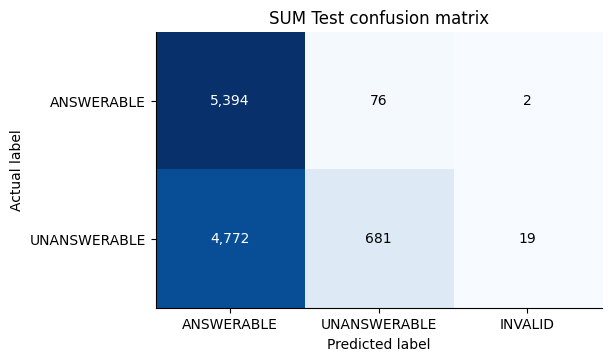

,Actual examples,Correct,Wrong label,INVALID,Wrong-label rate,Total error rate
Actual class,,,,,,
ANSWERABLE,5472,5394,76,2,1.39%,1.43%
UNANSWERABLE,5472,681,4772,19,87.21%,87.55%


There were **76 false positives** (1.39% of answerable questions) and **4,772 false negatives** (87.21% of unanswerable questions). Of the true UNANSWERABLE rows, 19 additionally received INVALID responses and count as missed positives in recall.

,Row index,Pair ID,Question,Actual label,Prediction,Raw response (repr),Hit token limit
Error type,,,,,,,
False positive,327,18087,Given the function \(f(x) = x^2 + 2ax + 4\) an...,ANSWERABLE,UNANSWERABLE,'UNANSWERABLE',False
False negative,2,34731,The product of two positive integers is 18. Th...,UNANSWERABLE,ANSWERABLE,'ANSWERABLE',False
INVALID,703,34187,Find 2 \cdot 5^{-1} + 8 \cdot 11^{-1} \pmod{0}...,UNANSWERABLE,INVALID,'UNANSWERABLE.',False


In [4]:
show_evaluation('SUM Test', sum_metrics, sum_matrix)
show_class_errors(sum_matrix)
display(Markdown(interpret_errors(sum_matrix)))
show_examples(sum_predictions, 'pair_id')

## 4. UMWP Results & Analysis

UMWP is an external mathematical word problem benchmark. The analysis uses the complete saved UMWP run.

The examples use the same selection rule as SUM Test.

,Examples,Accuracy,Precision (UNANSWERABLE),Recall (UNANSWERABLE),F1 (UNANSWERABLE),Invalid outputs
Dataset,,,,,,
UMWP,"5,200",55.69%,94.63%,12.19%,21.60%,20 (0.38%)


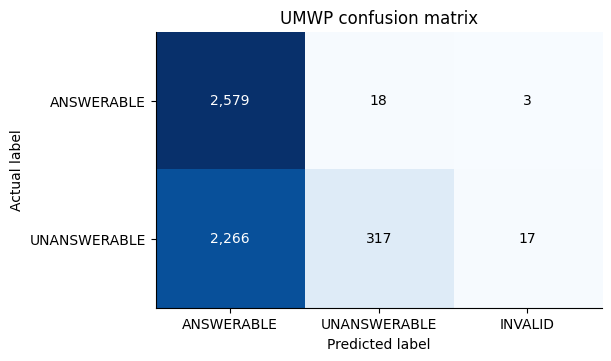

,Actual examples,Correct,Wrong label,INVALID,Wrong-label rate,Total error rate
Actual class,,,,,,
ANSWERABLE,2600,2579,18,3,0.69%,0.81%
UNANSWERABLE,2600,317,2266,17,87.15%,87.81%


There were **18 false positives** (0.69% of answerable questions) and **2,266 false negatives** (87.15% of unanswerable questions). Of the true UNANSWERABLE rows, 17 additionally received INVALID responses and count as missed positives in recall.

,Row index,Question ID,Question,Actual label,Prediction,Raw response (repr),Hit token limit
Error type,,,,,,,
False positive,55,56,Matthew gave equal numbers of crackers to his ...,ANSWERABLE,UNANSWERABLE,'UNANSWERABLE',False
False negative,2601,2502,3 birds were sitting on the fence. 2 more bird...,UNANSWERABLE,ANSWERABLE,'ANSWERABLE',False
INVALID,1764,1765,On the last night that roller skate rink was o...,ANSWERABLE,INVALID,'ANSWWERABLE',False


In [5]:
show_evaluation('UMWP', umwp_metrics, umwp_matrix)
show_class_errors(umwp_matrix)
display(Markdown(interpret_errors(umwp_matrix)))
show_examples(umwp_predictions, 'id')

## 5. MATE Results & Analysis

MATE is the second external benchmark. The analysis uses the complete saved run on the fixed processed test file.

,Examples,Accuracy,Precision (UNANSWERABLE),Recall (UNANSWERABLE),F1 (UNANSWERABLE),Invalid outputs
Dataset,,,,,,
MATE,"9,586",52.85%,88.71%,6.72%,12.49%,52 (0.54%)


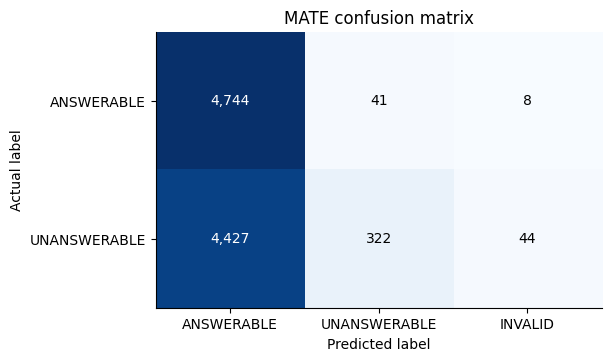

,Actual examples,Correct,Wrong label,INVALID,Wrong-label rate,Total error rate
Actual class,,,,,,
ANSWERABLE,4793,4744,41,8,0.86%,1.02%
UNANSWERABLE,4793,322,4427,44,92.36%,93.28%


There were **41 false positives** (0.86% of answerable questions) and **4,427 false negatives** (92.36% of unanswerable questions). Of the true UNANSWERABLE rows, 44 additionally received INVALID responses and count as missed positives in recall.

,Row index,Question ID,Question,Actual label,Prediction,Raw response (repr),Hit token limit
Error type,,,,,,,
False positive,52,53,"There are numbers 0.8, 1/2, 0.9, and 1/3. Find...",ANSWERABLE,UNANSWERABLE,'UNANSWERABLE',False
False negative,3,4,If the average (arithmetic mean) of either fiv...,UNANSWERABLE,ANSWERABLE,'ANSWERABLE',False
INVALID,19,20,There are an unspecified number of seventh gra...,UNANSWERABLE,INVALID,'ANSWWERABLE',False


In [6]:
show_evaluation('MATE', mate_metrics, mate_matrix)
show_class_errors(mate_matrix)
display(Markdown(interpret_errors(mate_matrix)))
show_examples(mate_predictions, 'id')

## 6. Dataset Comparison & Interpretation

Rates use each dataset's full run as the denominator for accuracy, INVALID rate, and prediction shares. Precision, recall and F1 use the UNANSWERABLE class. The metric chart shows INVALID separately because its scale is much smaller.

,ANSWERABLE,UNANSWERABLE,INVALID
Dataset,,,
SUM Test,10166 (92.89%),757 (6.92%),21 (0.19%)
UMWP,4845 (93.17%),335 (6.44%),20 (0.38%)
MATE,9171 (95.67%),363 (3.79%),52 (0.54%)


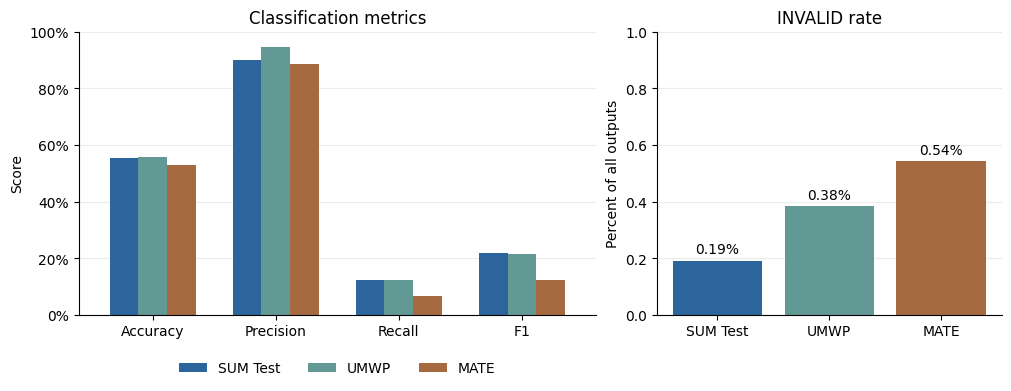

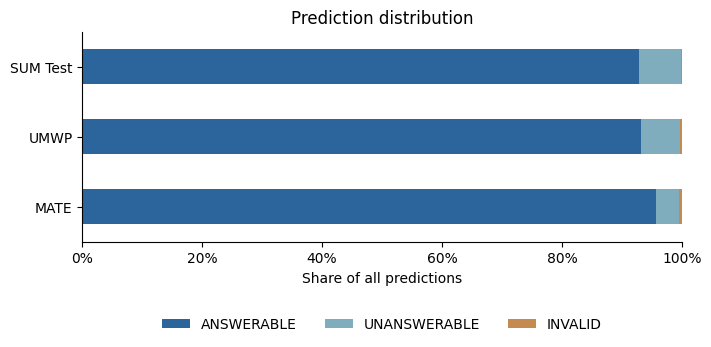

In [7]:
evaluations = {'SUM Test': (sum_metrics, sum_matrix), 'UMWP': (umwp_metrics, umwp_matrix), 'MATE': (mate_metrics, mate_matrix)}
metric_rates = pd.DataFrame({
    name: {label: metrics[key] for label, key in METRICS.items()}
    for name, (metrics, _) in evaluations.items()
})
metric_rates.index = ['Accuracy', 'Precision', 'Recall', 'F1']
invalid_rates = pd.Series({name: metrics['invalid_rate'] for name, (metrics, _) in evaluations.items()})
prediction_counts = pd.DataFrame({
    name: matrix.sum(axis=0) for name, (_, matrix) in evaluations.items()
}).T
prediction_shares = prediction_counts.div(prediction_counts.sum(axis=1), axis=0)
display((prediction_counts.astype(str) + ' (' + prediction_shares.map('{:.2%}'.format) + ')')
        .rename_axis('Dataset'))

colors = ['#2b659b', '#629995', '#a66a41']
fig, (ax_metrics, ax_invalid) = plt.subplots(
    1, 2, figsize=(10, 3.8), width_ratios=[3, 2], layout='constrained',
)
metric_rates.plot.bar(ax=ax_metrics, color=colors, rot=0, width=0.7)
ax_metrics.set(ylim=(0, 1), ylabel='Score', title='Classification metrics')
ax_metrics.yaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(xmax=1))
ax_metrics.legend(frameon=False, loc='upper center', bbox_to_anchor=(0.5, -0.12), ncol=3)
invalid_bars = ax_invalid.bar(invalid_rates.index, invalid_rates * 100, color=colors)
ax_invalid.bar_label(invalid_bars, labels=[f'{rate:.2%}' for rate in invalid_rates], padding=3)
ax_invalid.set(ylim=(0, 1), ylabel='Percent of all outputs', title='INVALID rate')
for ax in (ax_metrics, ax_invalid):
    ax.set_axisbelow(True)
    ax.grid(axis='y', alpha=0.25)
plt.show()
plt.close(fig)

fig, ax = plt.subplots(figsize=(7, 3.3), layout='constrained')
prediction_shares.plot.barh(ax=ax, stacked=True, color=['#2b659b', '#80adbd', '#c58a50'])
ax.invert_yaxis()
ax.set(xlim=(0, 1), xlabel='Share of all predictions', ylabel='', title='Prediction distribution')
ax.xaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(xmax=1))
ax.legend(loc='upper center', bbox_to_anchor=(0.5, -0.3), ncol=3, frameon=False)
plt.show()
plt.close(fig)

In [8]:
observations = []
for name, (metrics, matrix) in evaluations.items():
    answerable_share = prediction_shares.loc[name, 'ANSWERABLE']
    observations.append(
        f"- **{name}**: {answerable_share:.2%} of predictions were ANSWERABLE. "
        f"UNANSWERABLE precision was {metrics['precision_unanswerable']:.2%} and "
        f"recall was {metrics['recall_unanswerable']:.2%}. "
        f"The matrix records {matrix.loc['UNANSWERABLE', 'ANSWERABLE']:,} false negatives "
        f"and {matrix.loc['ANSWERABLE', 'UNANSWERABLE']:,} false positives."
    )
for target, reference in [('UMWP', 'SUM Test'), ('MATE', 'SUM Test'), ('MATE', 'UMWP')]:
    gap = 100 * (evaluations[target][0]['f1_unanswerable'] - evaluations[reference][0]['f1_unanswerable'])
    observations.append(f"- UNANSWERABLE F1 on {target} versus {reference}: {gap:+.2f} percentage points.")
display(Markdown("\n".join(observations)))

- **SUM Test**: 92.89% of predictions were ANSWERABLE. UNANSWERABLE precision was 89.96% and recall was 12.45%. The matrix records 4,772 false negatives and 76 false positives.
- **UMWP**: 93.17% of predictions were ANSWERABLE. UNANSWERABLE precision was 94.63% and recall was 12.19%. The matrix records 2,266 false negatives and 18 false positives.
- **MATE**: 95.67% of predictions were ANSWERABLE. UNANSWERABLE precision was 88.71% and recall was 6.72%. The matrix records 4,427 false negatives and 41 false positives.
- UNANSWERABLE F1 on UMWP versus SUM Test: -0.26 percentage points.
- UNANSWERABLE F1 on MATE versus SUM Test: -9.38 percentage points.
- UNANSWERABLE F1 on MATE versus UMWP: -9.11 percentage points.